In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# pip install pandas numpy matplotlib utilsforecast statsforecast

In [13]:
df = pd.read_csv("data/daily_sales_french_bakery.csv", parse_dates = ["ds"])
df.head()

,unique_id,ds,y,unit_price
0,12 MACARON,2022-07-13,10.0,10.0
1,12 MACARON,2022-07-14,0.0,10.0
2,12 MACARON,2022-07-15,0.0,10.0
3,12 MACARON,2022-07-16,10.0,10.0
4,12 MACARON,2022-07-17,30.0,10.0


In [3]:
df.shape

(57046, 4)

In [14]:
grouped_df = df.groupby("unique_id").filter(lambda x : len(x) >= 28).reset_index() # fitlering products with more than 28 records
grouped_df = grouped_df.drop(columns = ["unit_price"])

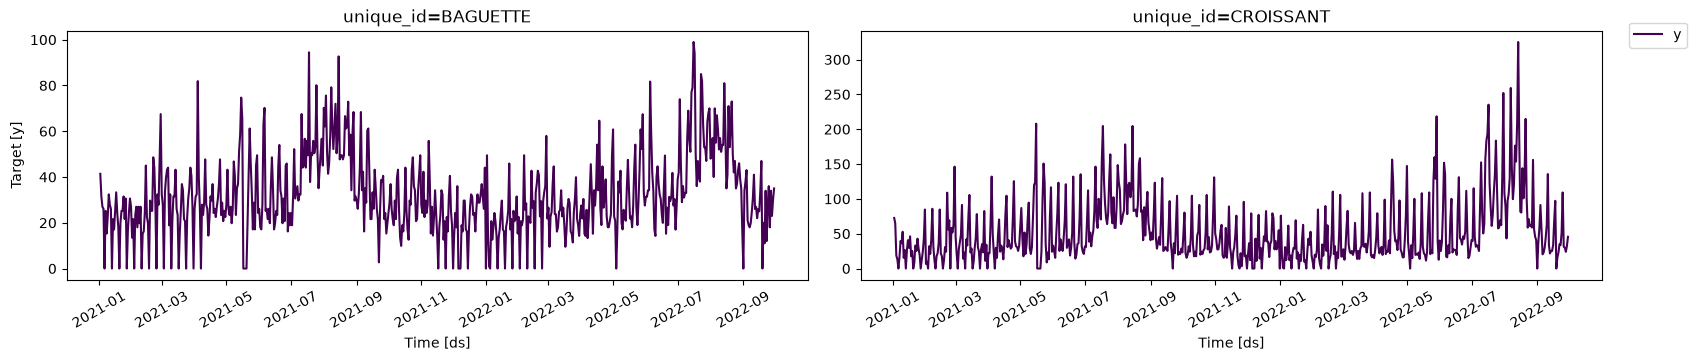

In [16]:
plot_series(df = grouped_df, ids = ["BAGUETTE", "CROISSANT"], palette = "viridis")

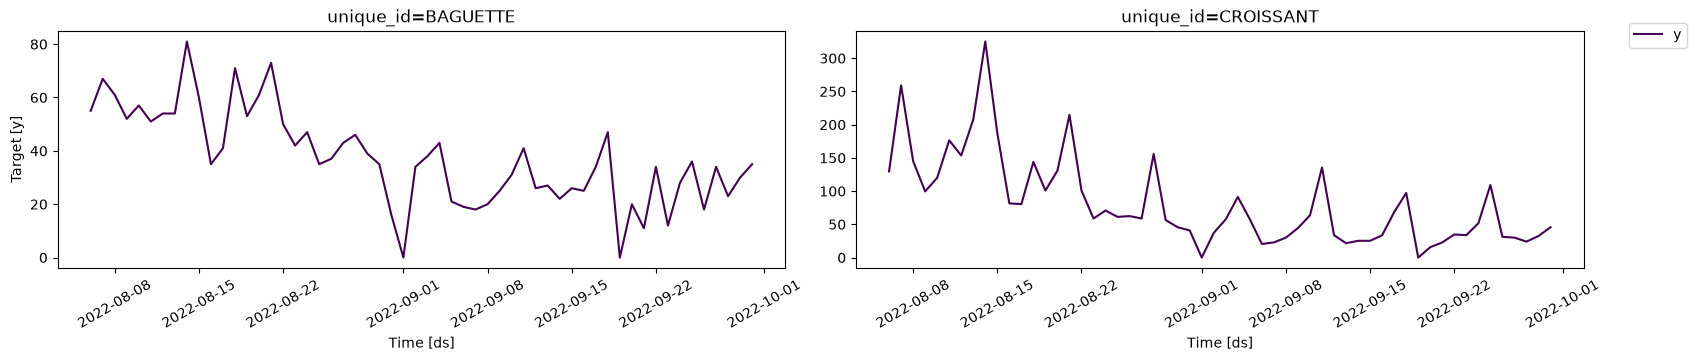

In [9]:
plot_series(
    df = grouped_df, 
    ids = ["BAGUETTE", "CROISSANT"], 
    palette = "viridis", 
    max_insample_length = 56 # only plotting the last 56 timestamps
)

### Baseline Models

In [21]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, HistoricAverage, WindowAverage, SeasonalNaive

In [23]:
horizon = 7 # forecast horizon of 7 days

models = [
    Naive(),
    HistoricAverage(),
    WindowAverage(window_size = 7),
    SeasonalNaive(season_length = 7)
]

sf = StatsForecast(models = models, freq = "D") # D = daily
sf.fit(df = grouped_df)
preds = sf.predict(h = horizon)

In [24]:
preds.head()

,unique_id,ds,Naive,HistoricAverage,WindowAverage,SeasonalNaive
0,12 MACARON,2022-09-29,10.0,8.974359,2.857143,0.0
1,12 MACARON,2022-09-30,10.0,8.974359,2.857143,0.0
2,12 MACARON,2022-10-01,10.0,8.974359,2.857143,10.0
3,12 MACARON,2022-10-02,10.0,8.974359,2.857143,0.0
4,12 MACARON,2022-10-03,10.0,8.974359,2.857143,0.0


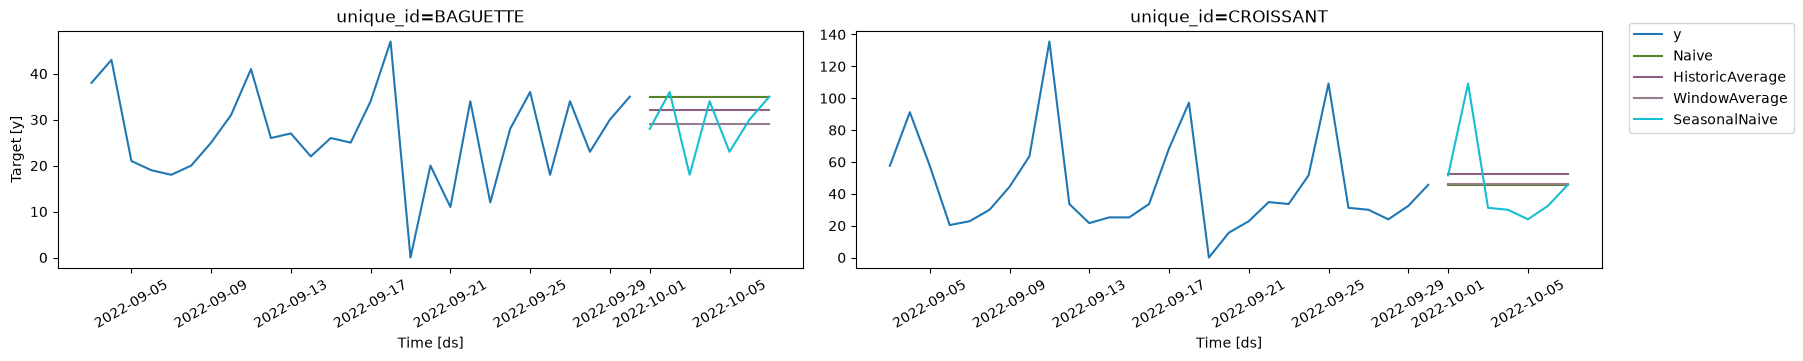

In [30]:
plot_series(
    df = grouped_df, 
    forecasts_df = preds,
    ids = ["BAGUETTE", "CROISSANT"], 
    # palette = "viridis", 
    max_insample_length = 28 # only plotting the last 56 timestamps
)

### Evaluating Baseline Models